In [17]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

breast_cancer = load_breast_cancer()

X_bc = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)
y_bc = pd.Series(breast_cancer.target, name="target")

print("Samples:", X_bc.shape[0])
print("Features:", X_bc.shape[1])

display(X_bc.head())

Samples: 569
Features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [18]:
print("Dataset Shape:", X_bc.shape)
print("Feature Names:", list(X_bc.columns))
print("Target Classes:", breast_cancer.target_names)

print("\nClass Distribution:")
print(y_bc.value_counts().sort_index())

display(X_bc.head())


Dataset Shape: (569, 30)
Feature Names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target Classes: ['malignant' 'benign']

Class Distribution:
0    212
1    357
Name: target, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [19]:
print("Missing Values:")
print(X_bc.isnull().sum())

print("\nTotal Missing Values:", X_bc.isnull().sum().sum())
print("Duplicate Rows:", X_bc.duplicated().sum())

Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 0


In [20]:
Q1 = X_bc.quantile(0.25)
Q3 = X_bc.quantile(0.75)
IQR = Q3 - Q1

outliers = ((X_bc < Q1 - 1.5 * IQR) | (X_bc > Q3 + 1.5 * IQR)).sum()

print("Potential Outliers:")
print(outliers)

Potential Outliers:
mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity            12
worst concave points        0
worst symmetry             23
worst fractal dimension    24
dtype: int64


In [21]:
print("Feature Data Types:")
print(X_bc.dtypes)

numerical = X_bc.select_dtypes(include="number").shape[1]
categorical = X_bc.shape[1] - numerical

print("\nNumerical Features:", numerical)
print("Categorical Features:", categorical)

Feature Data Types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64


In [22]:
stats = X_bc.describe().T
stats = stats[["mean", "50%", "min", "max", "std", "25%", "75%"]]
stats.columns = ["Mean", "Median", "Min", "Max", "Std", "Q1", "Q3"]
display(stats.round(3))

,Mean,Median,Min,Max,Std,Q1,Q3
mean radius,14.127,13.370,6.981,28.110,3.524,11.700,15.780
mean texture,19.290,18.840,9.710,39.280,4.301,16.170,21.800
mean perimeter,91.969,86.240,43.790,188.500,24.299,75.170,104.100
mean area,654.889,551.100,143.500,2501.000,351.914,420.300,782.700
mean smoothness,0.096,0.096,0.053,0.163,0.014,0.086,0.105
mean compactness,0.104,0.093,0.019,0.345,0.053,0.065,0.130
mean concavity,0.089,0.062,0.000,0.427,0.080,0.030,0.131
mean concave points,0.049,0.034,0.000,0.201,0.039,0.020,0.074
mean symmetry,0.181,0.179,0.106,0.304,0.027,0.162,0.196
mean fractal dimension,0.063,0.062,0.050,0.097,0.007,0.058,0.066


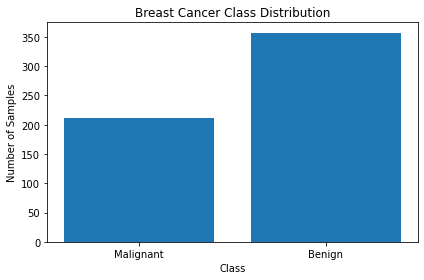

0    212
1    357
Name: target, dtype: int64


In [23]:
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)
counts = y_bc.value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Malignant", "Benign"], counts.values)
plt.title("Breast Cancer Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.savefig("figures/bc_class_distribution.png", dpi=300)
plt.show()
print(counts)

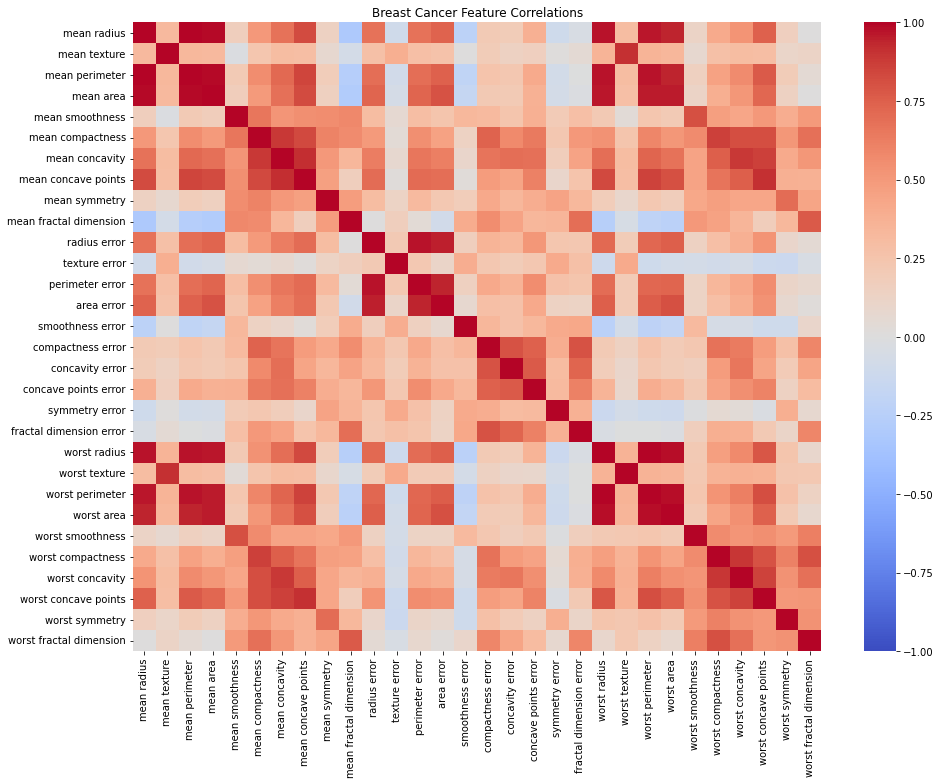

In [24]:
import seaborn as sns

corr = X_bc.corr(method="pearson")
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Breast Cancer Feature Correlations")
plt.tight_layout()
plt.savefig("figures/bc_correlation_heatmap.png", dpi=300)
plt.show()

In [25]:
import numpy as np
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
top_pairs = upper.stack().sort_values(key=abs, ascending=False).head(3)

print("Top 3 Strongest Correlations:")
print(top_pairs)


Top 3 Strongest Correlations:
mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64


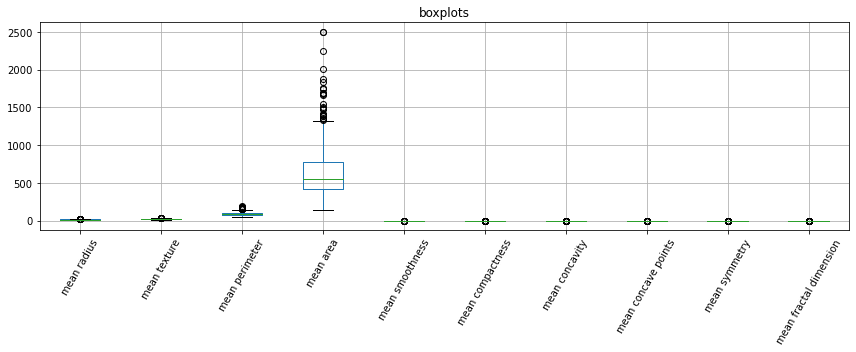

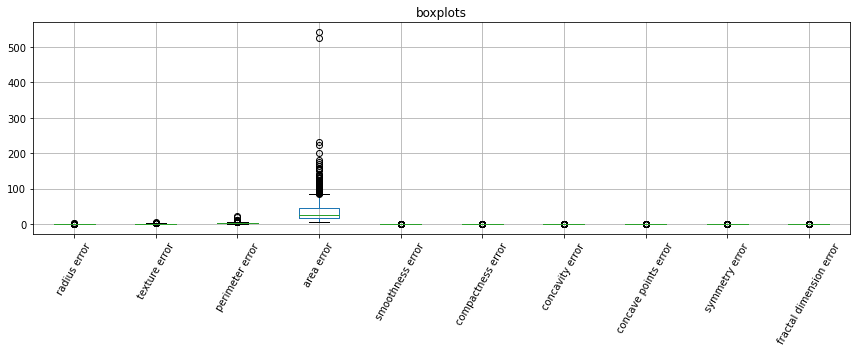

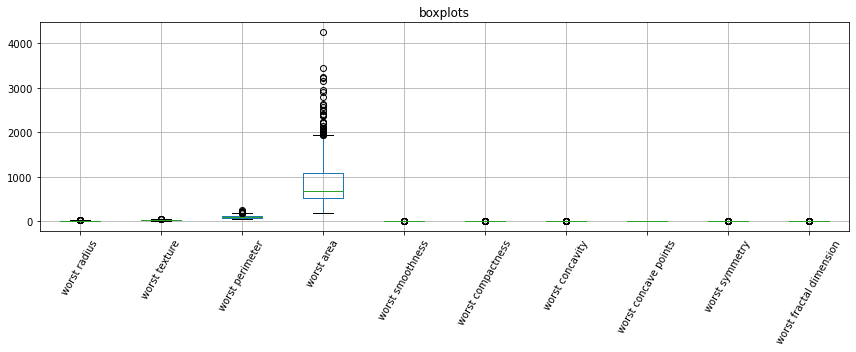

In [26]:

for i in range(0, 30, 10):
    cols = X_bc.columns[i:i+10]

    plt.figure(figsize=(12, 5))
    X_bc[cols].boxplot(rot=60)
    plt.title("boxplots")
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.savefig("figures/bc_boxplot_" + str(i//10+1) + ".png")
    plt.show()


In [27]:
from sklearn.model_selection import train_test_split

seeds = [42, 52, 62]

idx, test_idx = train_test_split( X_bc.index, test_size=0.20, stratify=y_bc, random_state=42)
X_test = X_bc.loc[test_idx]
y_test = y_bc.loc[test_idx]
X_train = {}
X_val = {}
y_train = {}
y_val = {}

for s in seeds:
    tr, val = train_test_split(idx, test_size=0.125, stratify=y_bc.loc[idx], random_state=s)

    X_train[s] = X_bc.loc[tr]
    X_val[s] = X_bc.loc[val]
    y_train[s] = y_bc.loc[tr]
    y_val[s] = y_bc.loc[val]

print("train:", len(X_train[42]))
print("validation:", len(X_val[42]))
print("test:", len(X_test))


train: 398
validation: 57
test: 114


In [28]:
rows = []
for s in seeds:
    for name, y in [("train", y_train[s]), ("validation", y_val[s]), ("test", y_test)]:
        rows.append([s, name, len(y),
            round(len(y) / len(y_bc) * 100, 2),
            (y == 0).sum(),
            (y == 1).sum()])
split_table = pd.DataFrame(rows, columns=["seed", "subset", "count", "percent", "malignant", "benign"])
display(split_table)

,seed,subset,count,percent,malignant,benign
0,42,train,398,69.95,149,249
1,42,validation,57,10.02,21,36
2,42,test,114,20.04,42,72
3,52,train,398,69.95,149,249
4,52,validation,57,10.02,21,36
5,52,test,114,20.04,42,72
6,62,train,398,69.95,149,249
7,62,validation,57,10.02,21,36
8,62,test,114,20.04,42,72


In [29]:
for s in seeds:
    a = set(X_train[s].index)
    b = set(X_val[s].index)
    c = set(X_test.index)

    print("seed:", s)
    print("overlap:", len(a & b), len(a & c), len(b & c))
    print("total:", len(a | b | c))
    print("test same:", c == set(test_idx))

print("\ntrain indices:", X_train[42].index.tolist())
print("\nvalidation indices:", X_val[42].index.tolist())
print("\ntest indices:", X_test.index.tolist())



seed: 42
overlap: 0 0 0
total: 569
test same: True
seed: 52
overlap: 0 0 0
total: 569
test same: True
seed: 62
overlap: 0 0 0
total: 569
test same: True

train indices: [301, 390, 420, 356, 446, 56, 82, 221, 339, 364, 37, 263, 341, 210, 514, 234, 99, 533, 482, 69, 484, 192, 392, 81, 245, 529, 91, 35, 456, 351, 79, 272, 270, 177, 469, 46, 163, 181, 107, 108, 332, 48, 262, 362, 379, 531, 146, 382, 562, 325, 98, 377, 400, 532, 539, 500, 100, 438, 460, 274, 419, 207, 441, 172, 411, 315, 347, 144, 306, 148, 233, 57, 36, 372, 409, 282, 287, 416, 68, 369, 61, 478, 512, 278, 143, 265, 165, 474, 561, 413, 67, 432, 42, 236, 54, 374, 548, 401, 201, 458, 162, 159, 32, 171, 337, 229, 312, 277, 322, 304, 290, 436, 241, 106, 249, 348, 136, 334, 178, 2, 398, 368, 47, 503, 62, 554, 116, 546, 202, 89, 297, 124, 253, 521, 330, 5, 251, 538, 166, 182, 268, 195, 138, 19, 470, 286, 226, 414, 188, 59, 218, 510, 345, 430, 208, 8, 3, 160, 403, 149, 133, 65, 294, 371, 209, 509, 404, 179, 485, 357, 219, 547, 141,

In [30]:
from sklearn.preprocessing import StandardScaler
scalers = {}
X_train_scaled = {}
X_val_scaled = {}

for s in seeds:
    sc = StandardScaler()

    X_train_scaled[s] = pd.DataFrame(sc.fit_transform(X_train[s]),columns=X_bc.columns,index=X_train[s].index)
    X_val_scaled[s] = pd.DataFrame(sc.transform(X_val[s]),columns=X_bc.columns,index=X_val[s].index)

    scalers[s] = sc

X_test_scaled = pd.DataFrame(scalers[42].transform(X_test),columns=X_bc.columns,index=X_test.index)
print("scalers:", len(scalers))

scalers: 3


In [31]:
print("before scaling")
display(X_train[42].head())
print("after scaling")
display(X_train_scaled[42].head())

before scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


after scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


In [32]:
unscaled = {}
scaled = {}
for s in seeds:
    unscaled[s] = {"train": X_train[s],"val": X_val[s]}
    scaled[s] = {"train": X_train_scaled[s],"val": X_val_scaled[s] }

print("unscaled:", list(unscaled.keys()))
print("scaled:", list(scaled.keys()))

unscaled: [42, 52, 62]
scaled: [42, 52, 62]


In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
models = {}
runs = []

for s in seeds:
    for name, data in [("unscaled", unscaled), ("scaled", scaled)]:
        x = data[s]["train"]
        y = y_train[s]

        for d in [2, 3, 5, 10, None]:
            m = DecisionTreeClassifier(max_depth=d, random_state=s)
            m.fit(x, y)
            key = ("tree", name, str(d), s)
            models[key] = m
            runs.append(["bc_tree_" + name + "_d" + str(d) + "_s" + str(s),"tree", name, str(d), s])

        for k in [1, 3, 5, 7, 11]:
            m = KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="euclidean")
            m.fit(x, y)

            key = ("knn", name, str(k), s)
            models[key] = m
            runs.append(["bc_knn_" + name + "_k" + str(k) + "_s" + str(s),"knn", name, str(k), s])
        m = GaussianNB()
        m.fit(x, y)
        key = ("gnb", name, "default", s)
        models[key] = m
        runs.append(["bc_gnb_" + name + "_default_s" + str(s),"gnb", name, "default", s])
print("total models:", len(models))

total models: 66


In [34]:
from sklearn.metrics import accuracy_score, f1_score
results = []
for r in runs:
    exp_id, alg, name, param, s = r
    m = models[(alg, name, param, s)]

    x = unscaled[s]["train"] if name == "unscaled" else scaled[s]["train"]
    pred = m.predict(x)
    results.append([
        exp_id, "Breast Cancer", alg, name, param, s,
        accuracy_score(y_train[s], pred),
        f1_score(y_train[s], pred, average="macro")])

results_df = pd.DataFrame(results, columns=[
    "id", "dataset", "algorithm", "representation",
    "parameter", "seed", "train_accuracy", "train_f1"])
display(results_df)

,id,dataset,algorithm,representation,parameter,seed,train_accuracy,train_f1
0,bc_tree_unscaled_d2_s42,Breast Cancer,tree,unscaled,2,42,0.954774,0.951595
1,bc_tree_unscaled_d3_s42,Breast Cancer,tree,unscaled,3,42,0.972362,0.970031
2,bc_tree_unscaled_d5_s42,Breast Cancer,tree,unscaled,5,42,0.997487,0.997314
3,bc_tree_unscaled_d10_s42,Breast Cancer,tree,unscaled,10,42,1.000000,1.000000
4,bc_tree_unscaled_dNone_s42,Breast Cancer,tree,unscaled,None,42,1.000000,1.000000
...,...,...,...,...,...,...,...,...
61,bc_knn_scaled_k3_s62,Breast Cancer,knn,scaled,3,62,0.984925,0.983820
62,bc_knn_scaled_k5_s62,Breast Cancer,knn,scaled,5,62,0.972362,0.970294
63,bc_knn_scaled_k7_s62,Breast Cancer,knn,scaled,7,62,0.969849,0.967453
64,bc_knn_scaled_k11_s62,Breast Cancer,knn,scaled,11,62,0.972362,0.970209


In [35]:


print(results_df.groupby("algorithm").size())
print("total:", len(results_df))

algorithm
gnb      6
knn     30
tree    30
dtype: int64
total: 66


In [36]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

val_acc = []
val_prec = []
val_rec = []
val_f1 = []
val_auc = []

for r in runs:
    exp_id, alg, name, param, s = r
    m = models[(alg, name, param, s)]
    x = unscaled[s]["val"] if name == "unscaled" else scaled[s]["val"]
    y = y_val[s]

    pred = m.predict(x)
    prob = m.predict_proba(x)
    p0 = prob[:, list(m.classes_).index(0)]
    auc_score = roc_auc_score((y == 0).astype(int), p0)

    val_acc.append(accuracy_score(y, pred))
    val_prec.append(precision_score(y, pred, average="macro", zero_division=0))
    val_rec.append(recall_score(y, pred, average="macro", zero_division=0))
    val_f1.append(f1_score(y, pred, average="macro", zero_division=0))
    val_auc.append(auc_score)

results_df["val_accuracy"] = val_acc
results_df["val_precision"] = val_prec
results_df["val_recall"] = val_rec
results_df["val_f1"] = val_f1
results_df["val_auc"] = val_auc
display(results_df.round(4))

,id,dataset,algorithm,representation,parameter,seed,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_auc
0,bc_tree_unscaled_d2_s42,Breast Cancer,tree,unscaled,2,42,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,bc_tree_unscaled_d3_s42,Breast Cancer,tree,unscaled,3,42,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,bc_tree_unscaled_d5_s42,Breast Cancer,tree,unscaled,5,42,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,bc_tree_unscaled_d10_s42,Breast Cancer,tree,unscaled,10,42,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,bc_tree_unscaled_dNone_s42,Breast Cancer,tree,unscaled,None,42,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,bc_knn_scaled_k3_s62,Breast Cancer,knn,scaled,3,62,0.9849,0.9838,0.9825,0.9865,0.9762,0.9810,0.9974
62,bc_knn_scaled_k5_s62,Breast Cancer,knn,scaled,5,62,0.9724,0.9703,0.9825,0.9865,0.9762,0.9810,0.9993
63,bc_knn_scaled_k7_s62,Breast Cancer,knn,scaled,7,62,0.9698,0.9675,1.0000,1.0000,1.0000,1.0000,1.0000
64,bc_knn_scaled_k11_s62,Breast Cancer,knn,scaled,11,62,0.9724,0.9702,1.0000,1.0000,1.0000,1.0000,1.0000


In [37]:
from sklearn.metrics import confusion_matrix
problems = []
for r in runs:
    exp_id, alg, name, param, s = r
    m = models[(alg, name, param, s)]
    x = unscaled[s]["val"] if name == "unscaled" else scaled[s]["val"]
    y = y_val[s]
    pred = m.predict(x)
    cm = confusion_matrix(y, pred, labels=[0, 1])

    for i in range(2):
        if cm[:, i].sum() == 0:
            problems.append([exp_id, i, "precision"])
        if cm[i, :].sum() == 0:
            problems.append([exp_id, i, "recall"])

print("undefined metrics:", len(problems))
display(pd.DataFrame(problems, columns=["id", "class", "metric"]))

undefined metrics: 0


,id,class,metric


In [38]:
results_df = results_df[["id", "dataset", "seed", "algorithm", "representation", "parameter","train_accuracy", "train_f1", "val_accuracy", "val_precision","val_recall", "val_f1", "val_auc"]]
print("total runs:", len(results_df))
display(results_df.round(4))

total runs: 66


,id,dataset,seed,algorithm,representation,parameter,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_auc
0,bc_tree_unscaled_d2_s42,Breast Cancer,42,tree,unscaled,2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,bc_tree_unscaled_d3_s42,Breast Cancer,42,tree,unscaled,3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,bc_tree_unscaled_d5_s42,Breast Cancer,42,tree,unscaled,5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,bc_tree_unscaled_d10_s42,Breast Cancer,42,tree,unscaled,10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,bc_tree_unscaled_dNone_s42,Breast Cancer,42,tree,unscaled,None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,bc_knn_scaled_k3_s62,Breast Cancer,62,knn,scaled,3,0.9849,0.9838,0.9825,0.9865,0.9762,0.9810,0.9974
62,bc_knn_scaled_k5_s62,Breast Cancer,62,knn,scaled,5,0.9724,0.9703,0.9825,0.9865,0.9762,0.9810,0.9993
63,bc_knn_scaled_k7_s62,Breast Cancer,62,knn,scaled,7,0.9698,0.9675,1.0000,1.0000,1.0000,1.0000,1.0000
64,bc_knn_scaled_k11_s62,Breast Cancer,62,knn,scaled,11,0.9724,0.9702,1.0000,1.0000,1.0000,1.0000,1.0000


In [39]:
metrics = ["train_accuracy", "train_f1", "val_accuracy","val_precision", "val_recall", "val_f1", "val_auc"]
summary = results_df.groupby(["algorithm", "representation", "parameter"])[metrics].agg(["mean", "std"]).reset_index()
summary.columns = ["_".join(str(x) for x in col if x)for col in summary.columns]

print("configurations:", len(summary))
display(summary.round(4))

configurations: 22


,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_auc_mean,val_auc_std
0,gnb,scaled,default,0.9355,0.0052,0.9307,0.0058,0.9298,0.0175,0.9239,0.0140,0.9279,0.0289,0.9248,0.0201,0.9757,0.0146
1,gnb,unscaled,default,0.9372,0.0044,0.9323,0.0049,0.9415,0.0203,0.9384,0.0164,0.9372,0.0308,0.9369,0.0226,0.9797,0.0126
2,knn,scaled,1,1.0000,0.0000,1.0000,0.0000,0.9415,0.0203,0.9410,0.0283,0.9339,0.0160,0.9369,0.0213,0.9339,0.0160
3,knn,scaled,11,0.9715,0.0015,0.9694,0.0015,0.9649,0.0351,0.9746,0.0250,0.9524,0.0476,0.9608,0.0395,0.9945,0.0048
4,knn,scaled,3,0.9807,0.0038,0.9793,0.0041,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9793,0.0162
5,knn,scaled,5,0.9740,0.0029,0.9721,0.0032,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9795,0.0174
6,knn,scaled,7,0.9724,0.0025,0.9702,0.0028,0.9708,0.0268,0.9784,0.0197,0.9603,0.0364,0.9677,0.0297,0.9782,0.0194
7,knn,unscaled,1,1.0000,0.0000,1.0000,0.0000,0.8889,0.0506,0.8836,0.0491,0.8757,0.0630,0.8786,0.0566,0.8757,0.0630
8,knn,unscaled,11,0.9447,0.0025,0.9404,0.0028,0.9240,0.0101,0.9351,0.0145,0.9034,0.0120,0.9155,0.0113,0.9605,0.0311
9,knn,unscaled,3,0.9590,0.0038,0.9558,0.0042,0.9006,0.0405,0.8998,0.0420,0.8849,0.0467,0.8910,0.0449,0.9299,0.0235


In [40]:
summary["config_id"] = (summary["algorithm"] + "_" + summary["representation"] + "_" + summary["parameter"])
summary = summary.sort_values(["val_f1_mean", "val_accuracy_mean", "val_f1_std", "config_id"],ascending=[False, False, True, True])
best = summary.iloc[0]
print("best configuration:", best["config_id"])
print("mean validation f1:", round(best["val_f1_mean"], 4))
print("mean validation accuracy:", round(best["val_accuracy_mean"], 4))

best configuration: knn_scaled_7
mean validation f1: 9.677e-01
mean validation accuracy: 0.9708


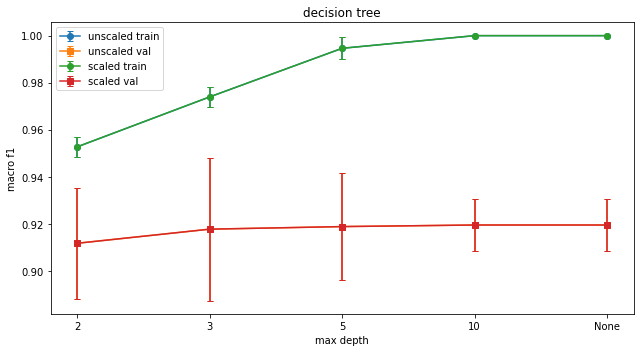

In [41]:
tree = summary[summary["algorithm"] == "tree"].copy()
depths = ["2", "3", "5", "10", "None"]
plt.figure(figsize=(9, 5))

for name in ["unscaled", "scaled"]:
    a = tree[tree["representation"] == name].set_index("parameter").loc[depths]

    plt.errorbar(depths, a["train_f1_mean"], yerr=a["train_f1_std"],
                 marker="o", capsize=3, label=name + " train")
    plt.errorbar(depths, a["val_f1_mean"], yerr=a["val_f1_std"],
                 marker="s", capsize=3, label=name + " val")
plt.xlabel("max depth")
plt.ylabel("macro f1")
plt.title("decision tree")
plt.legend()
plt.tight_layout()
plt.savefig("figures/bc_tree_comparison.png")
plt.show()

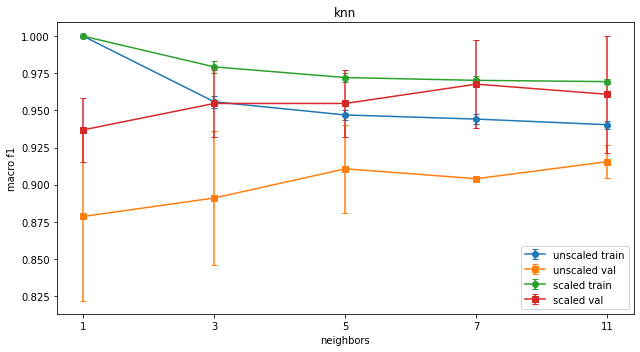

In [42]:
knn = summary[summary["algorithm"] == "knn"].copy()
ks = ["1", "3", "5", "7", "11"]

plt.figure(figsize=(9, 5))
for name in ["unscaled", "scaled"]:
    a = knn[knn["representation"] == name].set_index("parameter").loc[ks]
    plt.errorbar(ks, a["train_f1_mean"], yerr=a["train_f1_std"],
                 marker="o", capsize=3, label=name + " train")
    plt.errorbar(ks, a["val_f1_mean"], yerr=a["val_f1_std"],
                 marker="s", capsize=3, label=name + " val")

plt.xlabel("neighbors")
plt.ylabel("macro f1")
plt.title("knn")
plt.legend()
plt.tight_layout()
plt.savefig("figures/bc_knn_comparison.png")
plt.show()

In [43]:
alg = best["algorithm"]
rep = best["representation"]
param = best["parameter"]

model = models[(alg, rep, param, 42)]
x = X_test_scaled if rep == "scaled" else X_test

test_pred = model.predict(x)
test_prob = model.predict_proba(x)

p0 = test_prob[:, list(model.classes_).index(0)]
test_auc = roc_auc_score((y_test == 0).astype(int), p0)
test_acc = accuracy_score(y_test, test_pred)
test_prec = precision_score(y_test, test_pred, average="macro", zero_division=0)
test_rec = recall_score(y_test, test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)

print("accuracy:", round(test_acc, 4))
print("precision:", round(test_prec, 4))
print("recall:", round(test_rec, 4))
print("f1:", round(test_f1, 4))
print("auc:", round(test_auc, 4))

accuracy: 0.9737
precision: 0.98
recall: 0.9643
f1: 0.9713
auc: 0.9888


In [44]:
from sklearn.metrics import classification_report
print(classification_report(y_test, test_pred,labels=[0, 1],target_names=["malignant", "benign"],zero_division=0))

              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [45]:
final_table = pd.DataFrame([{"dataset": "Breast Cancer","configuration": best["config_id"], "seed": 42,
    "val_f1_mean": best["val_f1_mean"],
    "val_f1_std": best["val_f1_std"],
    "test_accuracy": test_acc,
    "test_precision": test_prec,
    "test_recall": test_rec,
    "test_f1": test_f1,
    "test_auc": test_auc}])
display(final_table.round(4))

,dataset,configuration,seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,Breast Cancer,knn_scaled_7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888


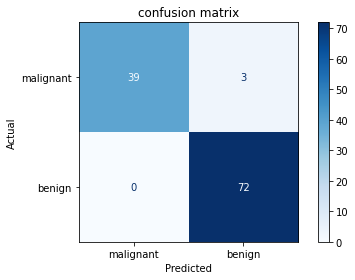

[[39  3]
 [ 0 72]]


In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["malignant", "benign"]).plot(cmap="Blues", values_format="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("confusion matrix")
plt.tight_layout()
plt.savefig("figures/bc_confusion_matrix.png")
plt.show()
print(cm)

In [47]:
tp = cm[0, 0]
fn = cm[0, 1]
fp = cm[1, 0]
tn = cm[1, 1]

p = tp / (tp + fp) if tp + fp > 0 else None
r = tp / (tp + fn) if tp + fn > 0 else None
f = 2*p*r / (p+r) if p is not None and r is not None and p+r > 0 else None

print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
print("manual precision:", p)
print("manual recall:", r)
print("manual f1:", f)

TP: 39 FP: 0 FN: 3 TN: 72
manual precision: 1.0
manual recall: 0.9285714285714286
manual f1: 0.962962962962963


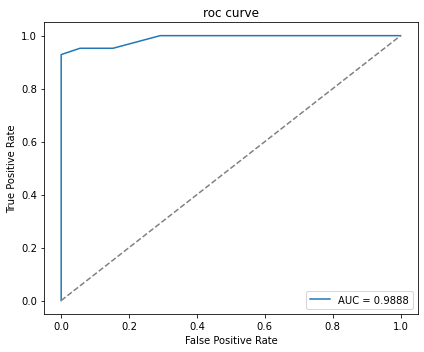

In [48]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve((y_test == 0).astype(int), p0)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label="AUC = " + str(round(test_auc, 4)))
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("roc curve")
plt.legend()
plt.tight_layout()
plt.savefig("figures/bc_roc_curve.png")
plt.show()

In [49]:
errors = pd.DataFrame({"actual": y_test,"predicted": test_pred}, index=X_test.index)
errors = errors[errors["actual"] != errors["predicted"]]
print("wrong predictions:", len(errors))
display(errors.head())

wrong predictions: 3


,actual,predicted
41,0,1
73,0,1
205,0,1


In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

km_models = {}
km_rows = []

for s in seeds:
    for name, data in [("unscaled", unscaled), ("scaled", scaled)]:
        x = data[s]["train"]
        v = data[s]["val"]

        km = KMeans(n_clusters=2, random_state=s, n_init=10)
        km.fit(x)
        pred = km.predict(v)
        n = len(set(pred))

        ari = adjusted_rand_score(y_val[s], pred)

        if 1 < n < len(v):
            sil = silhouette_score(v, pred)
        else:
            sil = np.nan

        km_models[(name, s)] = km

        km_rows.append([
            "bc_kmeans_" + name + "_s" + str(s),
            "Breast Cancer", name, s, 2,
            km.inertia_, ari, sil
        ])

km_df = pd.DataFrame(km_rows, columns=[
    "id", "dataset", "representation", "seed",
    "clusters", "train_inertia", "val_ari", "val_silhouette"
])

display(km_df.round(4))

,id,dataset,representation,seed,clusters,train_inertia,val_ari,val_silhouette
0,bc_kmeans_unscaled_s42,Breast Cancer,unscaled,42,2,5.156538e+07,0.3995,0.6387
1,bc_kmeans_scaled_s42,Breast Cancer,scaled,42,2,7.918810e+03,0.4516,0.2854
2,bc_kmeans_unscaled_s52,Breast Cancer,unscaled,52,2,4.919078e+07,0.6122,0.6975
3,bc_kmeans_scaled_s52,Breast Cancer,scaled,52,2,8.003001e+03,0.5586,0.3750
4,bc_kmeans_unscaled_s62,Breast Cancer,unscaled,62,2,5.305649e+07,0.5013,0.6958
5,bc_kmeans_scaled_s62,Breast Cancer,scaled,62,2,7.922515e+03,0.7336,0.2758


In [51]:

km_summary = km_df.groupby(["dataset", "representation"])[
    ["train_inertia", "val_ari", "val_silhouette"]
].agg(["mean", "std"]).reset_index()

km_summary.columns = [
    "_".join(str(a) for a in col if a)
    for col in km_summary.columns
]

counts = km_df.groupby(["dataset", "representation"])["val_silhouette"].count().values

km_summary["valid_silhouette_seeds"] = counts

display(km_summary.round(4))


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_seeds
0,Breast Cancer,scaled,7.948109e+03,4.757430e+01,0.5813,0.1424,0.3121,0.0547,3
1,Breast Cancer,unscaled,5.127088e+07,1.949607e+06,0.5043,0.1064,0.6773,0.0334,3


In [52]:
km_preds = {}
km_test = []

for name in ["unscaled", "scaled"]:
    km = km_models[(name, 42)]
    x = X_test if name == "unscaled" else X_test_scaled

    pred = km.predict(x)
    km_preds[name] = pred
    ari = adjusted_rand_score(y_test, pred)

    if 1 < len(set(pred)) < len(x):
        sil = silhouette_score(x, pred)
    else:
        sil = np.nan

    km_test.append([
        "Breast Cancer", name, 42, ari, sil
    ])

    print(name)
    print(pd.Series(pred).value_counts().sort_index())

km_test_df = pd.DataFrame(km_test, columns=[
    "dataset", "representation", "seed",
    "test_ari", "test_silhouette"
])

display(km_test_df.round(4))


unscaled
0    28
1    86
dtype: int64
scaled
0    40
1    74
dtype: int64


,dataset,representation,seed,test_ari,test_silhouette
0,Breast Cancer,unscaled,42,0.5585,0.7120
1,Breast Cancer,scaled,42,0.7354,0.3251


In [53]:
for name in ["unscaled", "scaled"]:
    tab = pd.crosstab(
        y_test,
        pd.Series(km_preds[name], index=y_test.index, name="cluster"))

    print(name)
    display(tab)

unscaled


cluster,0,1
target,,
0,28,14
1,0,72


scaled


cluster,0,1
target,,
0,37,5
1,3,69


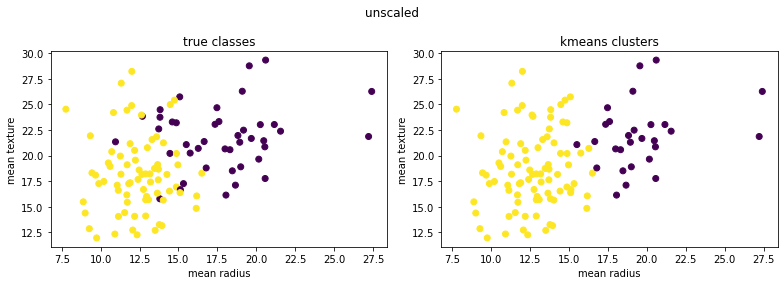

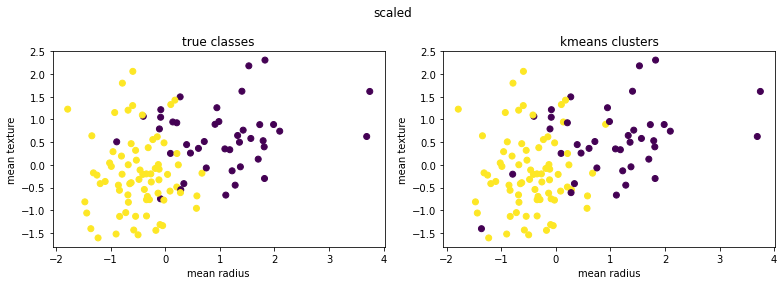

In [54]:
cols = ["mean radius", "mean texture"]
for name in ["unscaled", "scaled"]:
    x = X_test if name == "unscaled" else X_test_scaled
    pred = km_preds[name]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    ax[0].scatter(x[cols[0]], x[cols[1]], c=y_test, cmap="viridis")
    ax[0].set_title("true classes")
    ax[1].scatter(x[cols[0]], x[cols[1]], c=pred, cmap="viridis")
    ax[1].set_title("kmeans clusters")
    for a in ax:
        a.set_xlabel(cols[0])
        a.set_ylabel(cols[1])

    plt.suptitle(name)
    plt.tight_layout()
    plt.savefig("figures/bc_kmeans_" + name + ".png")
    plt.show()

In [40]:
print("kmeans runs:", len(km_df))
print("summary rows:", len(km_summary))
print("test rows:", len(km_test_df))
print("saved figures:")
print([f for f in os.listdir("figures") if f.startswith("bc_kmeans")])

kmeans runs: 6
summary rows: 2
test rows: 2
saved figures:
['bc_kmeans_scaled.png', 'bc_kmeans_unscaled.png']


In [41]:
print("classifier fits:", len(results_df))
print("kmeans fits:", len(km_df))
print("total fits:", len(results_df) + len(km_df))

classifier fits: 66
kmeans fits: 6
total fits: 72


In [42]:
results_df.to_csv("bc_classifier_runs.csv", index=False)
summary.to_csv("bc_classifier_summary.csv", index=False)
final_table.to_csv("bc_classifier_test.csv", index=False)
km_df.to_csv("bc_kmeans_runs.csv", index=False)
km_summary.to_csv("bc_kmeans_summary.csv", index=False)
km_test_df.to_csv("bc_kmeans_test.csv", index=False)

print("6 csv files saved")

6 csv files saved


In [46]:
for i, name in enumerate(["unscaled", "scaled"]):
    counts = pd.Series(km_preds[name]).value_counts()

    for k in range(3):
        km_test_df.loc[i, "cluster_" + str(k) + "_count"] = int(counts.get(k, 0))

km_test_df.to_csv("bc_kmeans_test.csv", index=False)
display(km_test_df)

,dataset,representation,seed,test_ari,test_silhouette,cluster_0_count,cluster_1_count,cluster_2_count
0,Breast Cancer,unscaled,42,0.558488,0.711999,28.0,86.0,0.0
1,Breast Cancer,scaled,42,0.735381,0.325062,40.0,74.0,0.0
